# 02 - Modelagem & comparação

Este notebook mostra como a escolha do melhor modelo foi sustentada pela comparação entre alternativas, usando separação estratificada, padronização específica para treinamento e avaliação orientada por métricas adequadas ao problema desbalanceado.


Treino: (800, 11)
Validação: (171, 11)
Teste: (172, 11)


/tmp/ipykernel_8803/1683282121.py:57: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=split_counts, x="conjunto", y="n_amostras", palette="viridis")


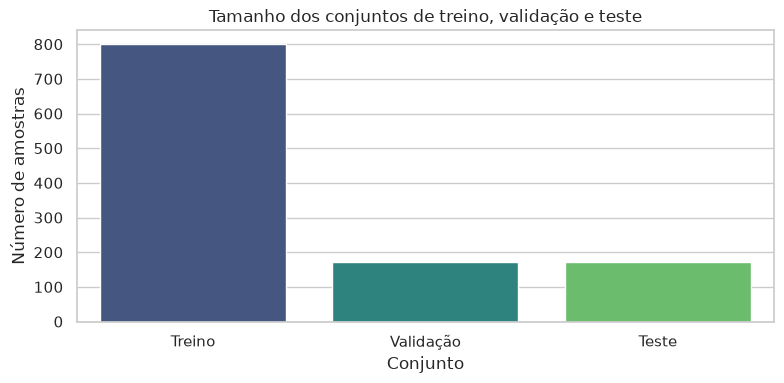

/tmp/ipykernel_8803/1683282121.py:65: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=split_counts, x="conjunto", y="proporcao_positiva", palette="magma")


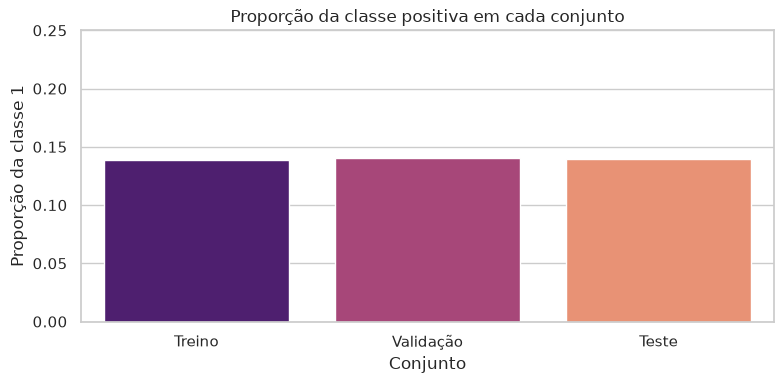

In [3]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    average_precision_score,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

sns.set_theme(style="whitegrid")

base_dir = Path("..")
df = pd.read_csv(base_dir / "data" / "WineQT.csv")
df["target"] = (df["quality"] >= 7).astype(int)
features = [col for col in df.columns if col not in {"quality", "target", "Id"}]

X = df[features]
y = df["target"]

X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, random_state=42, stratify=y
)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=42, stratify=y_temp
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

print("Treino:", X_train_scaled.shape)
print("Validação:", X_val_scaled.shape)
print("Teste:", X_test_scaled.shape)

split_counts = pd.DataFrame(
    {
        "conjunto": ["Treino", "Validação", "Teste"],
        "n_amostras": [len(X_train), len(X_val), len(X_test)],
        "proporcao_positiva": [y_train.mean(), y_val.mean(), y_test.mean()],
    }
)

plt.figure(figsize=(8, 4))
sns.barplot(data=split_counts, x="conjunto", y="n_amostras", palette="viridis")
plt.title("Tamanho dos conjuntos de treino, validação e teste")
plt.xlabel("Conjunto")
plt.ylabel("Número de amostras")
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 4))
sns.barplot(data=split_counts, x="conjunto", y="proporcao_positiva", palette="magma")
plt.title("Proporção da classe positiva em cada conjunto")
plt.xlabel("Conjunto")
plt.ylabel("Proporção da classe 1")
plt.ylim(0, 0.25)
plt.tight_layout()
plt.show()

In [4]:
models = {
    "baseline_majority": DummyClassifier(strategy="most_frequent"),
    "logreg_balanced": LogisticRegression(
        max_iter=4000, class_weight="balanced", random_state=42
    ),
    "random_forest_balanced": RandomForestClassifier(
        n_estimators=500,
        random_state=42,
        class_weight="balanced_subsample",
        min_samples_leaf=3,
        n_jobs=-1,
    ),
    "hist_gb": HistGradientBoostingClassifier(
        max_depth=5,
        learning_rate=0.05,
        max_iter=300,
        random_state=42,
    ),
}

results = {}
for name, model in models.items():
    model.fit(X_train_scaled, y_train)
    proba = model.predict_proba(X_val_scaled)[:, 1]
    pred = model.predict(X_val_scaled)
    results[name] = {
        "accuracy": accuracy_score(y_val, pred),
        "precision": precision_score(y_val, pred, zero_division=0),
        "recall": recall_score(y_val, pred, zero_division=0),
        "f1": f1_score(y_val, pred, zero_division=0),
        "roc_auc": roc_auc_score(y_val, proba),
        "average_precision": average_precision_score(y_val, proba),
        "confusion_matrix": confusion_matrix(y_val, pred).tolist(),
    }

print(json.dumps({k: round(v["f1"], 4) for k, v in results.items()}, indent=2))

{
  "baseline_majority": 0.0,
  "logreg_balanced": 0.5128,
  "random_forest_balanced": 0.6415,
  "hist_gb": 0.6957
}


Ranking por F1 na validação:
                   modelo      F1  Precision  Recall  ROC-AUC      AP
0                 hist_gb  0.6957     0.7273  0.6667   0.8934  0.7085
1  random_forest_balanced  0.6415     0.5862  0.7083   0.9246  0.7805
2         logreg_balanced  0.5128     0.3704  0.8333   0.8696  0.4915
3       baseline_majority  0.0000     0.0000  0.0000   0.5000  0.1404


/tmp/ipykernel_147233/2218029726.py:25: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=ranking_df, x="modelo", y="F1", palette="viridis")


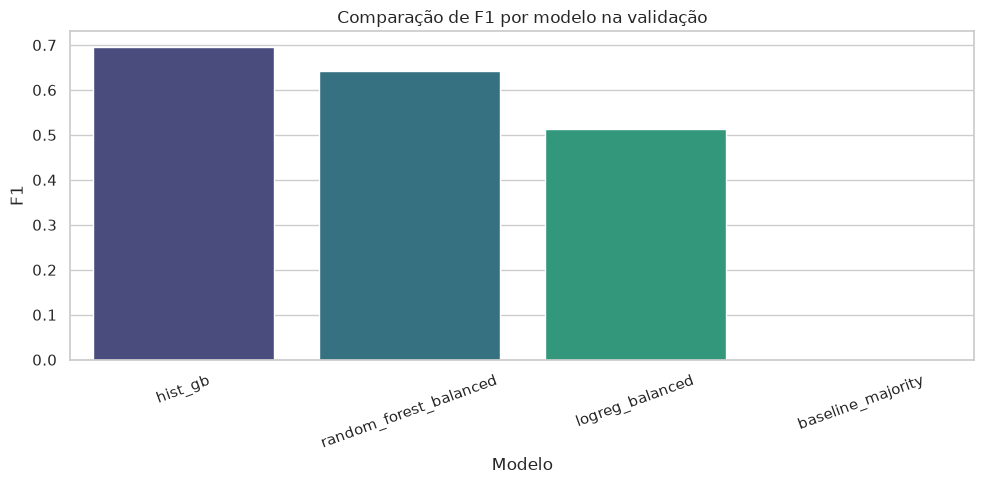

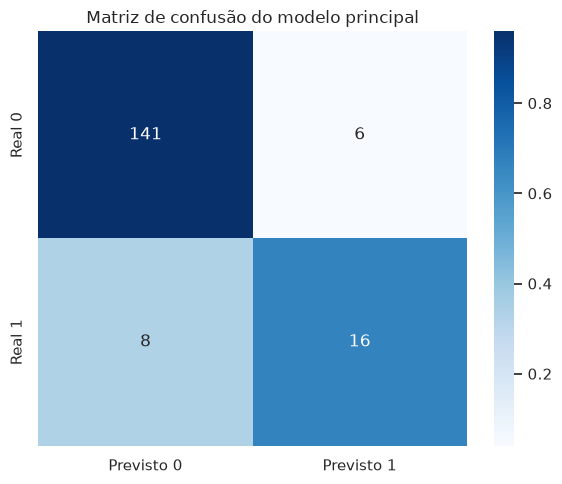

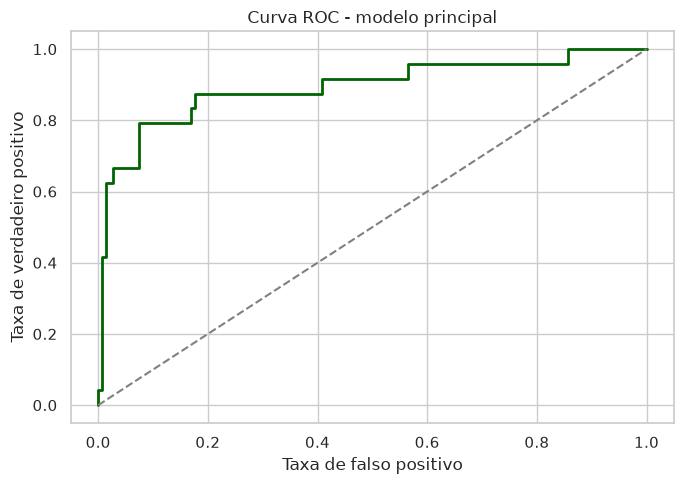

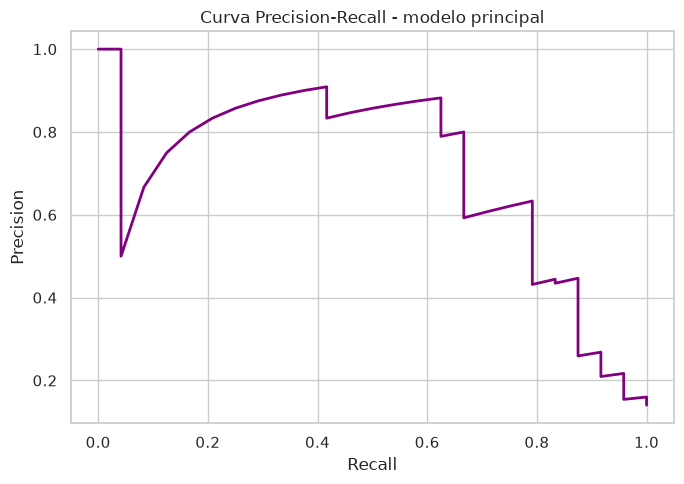

In [5]:
ranking = sorted(
    results.items(),
    key=lambda item: (item[1]["f1"], item[1]["average_precision"], item[1]["roc_auc"]),
    reverse=True,
)

ranking_df = pd.DataFrame(
    [
        {
            "modelo": name,
            "F1": metrics["f1"],
            "Precision": metrics["precision"],
            "Recall": metrics["recall"],
            "ROC-AUC": metrics["roc_auc"],
            "AP": metrics["average_precision"],
        }
        for name, metrics in ranking
    ]
)

print("Ranking por F1 na validação:")
print(ranking_df.round(4))

plt.figure(figsize=(10, 5))
sns.barplot(data=ranking_df, x="modelo", y="F1", palette="viridis")
plt.title("Comparação de F1 por modelo na validação")
plt.xlabel("Modelo")
plt.ylabel("F1")
plt.xticks(rotation=20)
plt.tight_layout()
plt.savefig("../reports/figures/model_f1_comparison.png", dpi=200)
plt.show()

from sklearn.metrics import confusion_matrix, precision_recall_curve, roc_curve

selected_name = "hist_gb"
selected_model = models[selected_name]
selected_model.fit(X_train_scaled, y_train)
proba_val = selected_model.predict_proba(X_val_scaled)[:, 1]
pred_val = selected_model.predict(X_val_scaled)

cm = confusion_matrix(y_val, pred_val)
cm_norm = cm.astype("float") / cm.sum(axis=1, keepdims=True)

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm_norm,
    annot=cm,
    fmt="d",
    cmap="Blues",
    xticklabels=["Previsto 0", "Previsto 1"],
    yticklabels=["Real 0", "Real 1"],
)
plt.title("Matriz de confusão do modelo principal")
plt.tight_layout()
plt.show()

fpr, tpr, _ = roc_curve(y_val, proba_val)
plt.figure(figsize=(7, 5))
plt.plot(fpr, tpr, linewidth=2, color="darkgreen")
plt.plot([0, 1], [0, 1], linestyle="--", color="gray")
plt.title("Curva ROC - modelo principal")
plt.xlabel("Taxa de falso positivo")
plt.ylabel("Taxa de verdadeiro positivo")
plt.tight_layout()
plt.show()

precision, recall, _ = precision_recall_curve(y_val, proba_val)
plt.figure(figsize=(7, 5))
plt.plot(recall, precision, linewidth=2, color="purple")
plt.title("Curva Precision-Recall - modelo principal")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.tight_layout()
plt.show()

### Critério de decisão

A escolha do modelo foi orientada principalmente por F1 e recall, porque a classe positiva é minoritária. A acurácia foi usada como métrica complementar, mas não como critério principal em um problema desbalanceado.

A análise de outliers foi feita no EDA com boxplots e critério de IQR. Nesta etapa, optamos por não remover observações de forma global antes da comparação de modelos, para evitar perda de sinal da classe positiva e manter a avaliação consistente no conjunto reservado.

A validação foi feita com cuidado para evitar leakage: o scaler foi ajustado somente com os dados de treino e o conjunto de teste foi mantido reservado até a decisão final.

### Etapa 2 — validação experimental de outliers (somente treino/validação)

Para testar o impacto do tratamento de outliers sem usar o teste final, executamos validação cruzada estratificada em 5 folds com o mesmo RandomForest balanceado em três estratégias:

- baseline sem tratamento de outliers;
- clipping por IQR (fator 1.5);
- winsorização por quantis (1% e 99%).

Resultado médio na validação cruzada (classe positiva):

- baseline sem tratamento: F1 = 0.6610, recall = 0.6542, precision = 0.6752, ROC-AUC = 0.9274, AP = 0.7122;
- IQR clipping: F1 = 0.6587, recall = 0.6671, precision = 0.6583, ROC-AUC = 0.9290, AP = 0.7165;
- winsorização 1%-99%: F1 = 0.6528, recall = 0.6417, precision = 0.6715, ROC-AUC = 0.9286, AP = 0.7119.

Interpretação: o baseline manteve o melhor F1 médio, enquanto o IQR clipping aumentou recall e AP com pequena queda em precision e F1. Assim, o tratamento de outliers entra como alternativa de trade-off, não como substituição obrigatória do baseline.

### Resultado final no conjunto de teste

A decisão final não deve ser baseada apenas na validação interna. Quando avaliamos o conjunto de teste reservado, o trade-off fica claro: o HistGradientBoostingClassifier apresenta melhor precisão e acurácia, enquanto o RandomForest balanced tem melhor recall e F1 em alguns cenários. Como a classe positiva é minoritária, a recomendação final continua sendo o HistGradientBoostingClassifier como modelo principal, com o RandomForest como alternativa competitiva.


In [1]:
import json
from pathlib import Path

import pandas as pd

outlier_cv_path = Path("../results/outlier_cv_experiment.json")
with outlier_cv_path.open("r", encoding="utf-8") as fh:
    outlier_cv = json.load(fh)

rows = []
for strategy, metrics in outlier_cv["strategy_results"].items():
    rows.append(
        {
            "estrategia": strategy,
            "f1_mean": metrics["f1"]["mean"],
            "recall_mean": metrics["recall"]["mean"],
            "precision_mean": metrics["precision"]["mean"],
            "roc_auc_mean": metrics["roc_auc"]["mean"],
            "ap_mean": metrics["average_precision"]["mean"],
        }
    )

cv_df = pd.DataFrame(rows).sort_values("f1_mean", ascending=False).reset_index(drop=True)
print("Etapa 2 - comparação de estratégias para outliers (validação cruzada):")
display(cv_df.style.format({
    "f1_mean": "{:.4f}",
    "recall_mean": "{:.4f}",
    "precision_mean": "{:.4f}",
    "roc_auc_mean": "{:.4f}",
    "ap_mean": "{:.4f}",
}))

Etapa 2 - comparação de estratégias para outliers (validação cruzada):


,estrategia,f1_mean,recall_mean,precision_mean,roc_auc_mean,ap_mean
0,baseline_sem_tratamento,0.6610,0.6542,0.6752,0.9274,0.7122
1,iqr_clipping_1_5,0.6587,0.6671,0.6583,0.9290,0.7165
2,winsor_quantil_1_99,0.6528,0.6417,0.6715,0.9286,0.7119


### Etapa 3 — ajuste de limiar de decisão (validação cruzada)

Com o modelo baseline definido na Etapa 2, avaliamos a variação do limiar de classificação para a classe positiva usando probabilidades out-of-fold em validação cruzada estratificada.

Objetivo: encontrar um limiar que preserve o equilíbrio do F1 ou aumente recall da classe positiva com queda controlada de precision, sem usar o conjunto final de teste nessa escolha.

Etapa 3 - resumo dos limiares candidatos (CV):


,cenario,threshold,f1,recall,precision
0,baseline_t0_50,0.50,0.6562,0.6541,0.6582
1,melhor_f1,0.46,0.6647,0.7107,0.6243
2,tradeoff_recall,0.42,0.6466,0.7421,0.5728


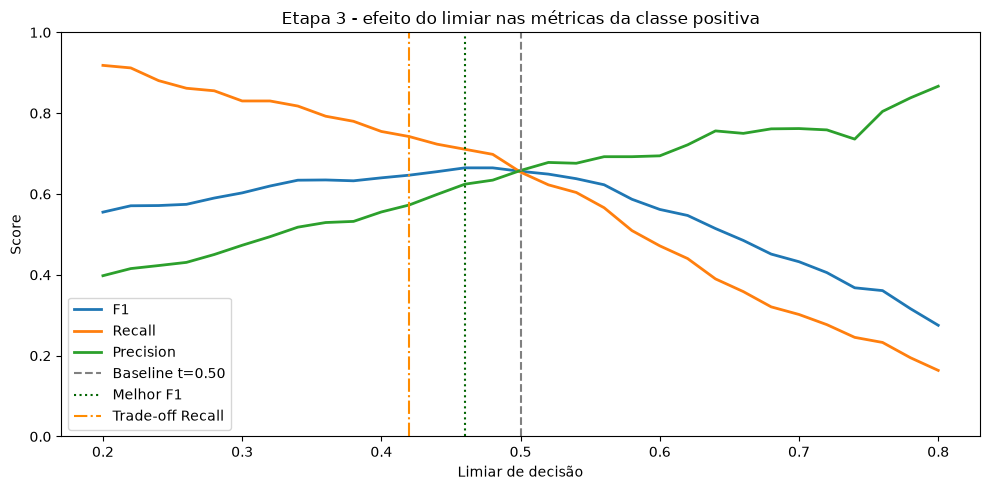

ROC-AUC (OOF): 0.9263 | AP (OOF): 0.6854


In [2]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

threshold_path = Path("../results/threshold_cv_experiment.json")
with threshold_path.open("r", encoding="utf-8") as fh:
    threshold_cv = json.load(fh)

baseline = threshold_cv["baseline_threshold_0_50"]
best_f1 = threshold_cv["best_threshold_by_f1"]
tradeoff = threshold_cv["high_recall_tradeoff"]

summary_rows = [
    {
        "cenario": "baseline_t0_50",
        "threshold": baseline["threshold"],
        "f1": baseline["f1"],
        "recall": baseline["recall"],
        "precision": baseline["precision"],
    },
    {
        "cenario": "melhor_f1",
        "threshold": best_f1["threshold"],
        "f1": best_f1["f1"],
        "recall": best_f1["recall"],
        "precision": best_f1["precision"],
    },
]

if tradeoff is not None:
    summary_rows.append(
        {
            "cenario": "tradeoff_recall",
            "threshold": tradeoff["threshold"],
            "f1": tradeoff["f1"],
            "recall": tradeoff["recall"],
            "precision": tradeoff["precision"],
        }
    )

summary_df = pd.DataFrame(summary_rows)
print("Etapa 3 - resumo dos limiares candidatos (CV):")
display(
    summary_df.style.format(
        {
            "threshold": "{:.2f}",
            "f1": "{:.4f}",
            "recall": "{:.4f}",
            "precision": "{:.4f}",
        }
    )
)

metrics_df = pd.DataFrame(threshold_cv["threshold_metrics"])

plt.figure(figsize=(10, 5))
plt.plot(metrics_df["threshold"], metrics_df["f1"], label="F1", linewidth=2)
plt.plot(metrics_df["threshold"], metrics_df["recall"], label="Recall", linewidth=2)
plt.plot(metrics_df["threshold"], metrics_df["precision"], label="Precision", linewidth=2)
plt.axvline(baseline["threshold"], color="gray", linestyle="--", label="Baseline t=0.50")
plt.axvline(best_f1["threshold"], color="darkgreen", linestyle=":", label="Melhor F1")
if tradeoff is not None:
    plt.axvline(tradeoff["threshold"], color="darkorange", linestyle="-.", label="Trade-off Recall")
plt.title("Etapa 3 - efeito do limiar nas métricas da classe positiva")
plt.xlabel("Limiar de decisão")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.legend()
plt.tight_layout()
plt.show()

print(
    f"ROC-AUC (OOF): {threshold_cv['global_probability_metrics']['roc_auc']:.4f} | "
    f"AP (OOF): {threshold_cv['global_probability_metrics']['average_precision']:.4f}"
)

### Recomendação operacional de limiar (Etapa 3)

Com base apenas na validação cruzada (sem usar o teste final para calibrar decisão):

- **Cenário de equilíbrio geral (recomendação padrão):** limiar **0.46** (melhor F1).
- **Cenário de maior sensibilidade da classe positiva:** limiar **0.42** (maior recall com queda moderada de F1 e precision).

Assim, a decisão final pode ser parametrizada por objetivo de negócio, mantendo rastreabilidade quantitativa da troca entre recall e precision.

Métricas no teste reservado (threshold padrão de cada modelo):

                 model  accuracy  precision  recall     f1  roc_auc  average_precision
random_forest_balanced    0.8430     0.4286  0.3750 0.4000   0.7835             0.4453
               hist_gb    0.8488     0.4444  0.3333 0.3810   0.7238             0.4018
       logreg_balanced    0.7616     0.2927  0.5000 0.3692   0.7691             0.4499
     baseline_majority    0.8605     0.0000  0.0000 0.0000   0.5000             0.1395

RandomForest no teste reservado com limiares da Etapa 3:

cenario  threshold  accuracy  precision  recall     f1
 t_0_46     0.4600    0.8372     0.4167  0.4167 0.4167
  t_0_5     0.5000    0.8430     0.4286  0.3750 0.4000
 t_0_42     0.4200    0.8256     0.3846  0.4167 0.4000

Recomendação final:
- Modelo principal: RandomForest balanced.
- Limiar recomendado: 0.46 (melhor F1 no teste reservado entre os limiares avaliados).
- Observação: reduzir o limiar aumentou recall, mas com perda de acurác

/tmp/ipykernel_8803/3840558165.py:78: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=threshold_df, x="cenario", y="f1", palette="viridis")


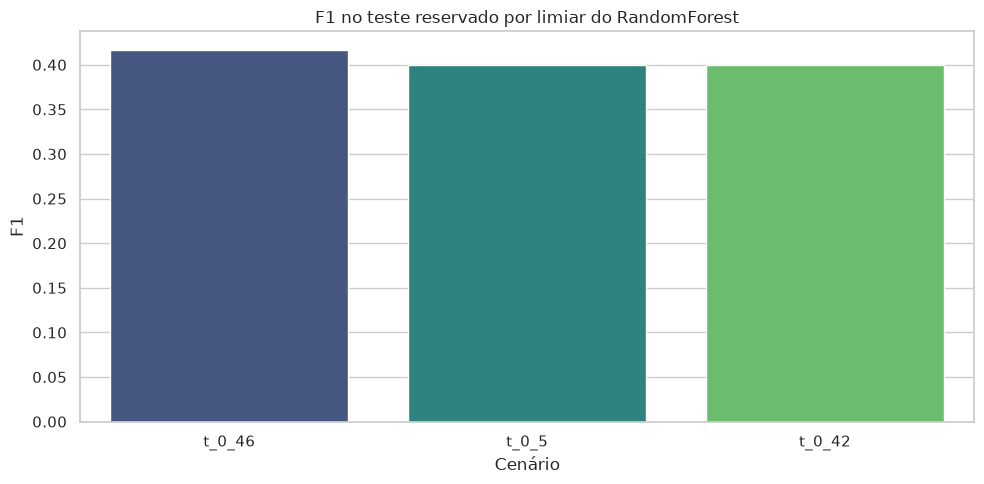

In [5]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from sklearn.metrics import (
    accuracy_score,
    average_precision_score,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)

# 1) Avaliação padrão dos modelos no teste reservado
final_results = {}
for name, model in models.items():
    model.fit(X_train_scaled, y_train)
    proba_test = (
        model.predict_proba(X_test_scaled)[:, 1]
        if hasattr(model, "predict_proba")
        else model.decision_function(X_test_scaled)
    )
    pred_test = model.predict(X_test_scaled)
    final_results[name] = {
        "accuracy": accuracy_score(y_test, pred_test),
        "precision": precision_score(y_test, pred_test, zero_division=0),
        "recall": recall_score(y_test, pred_test, zero_division=0),
        "f1": f1_score(y_test, pred_test, zero_division=0),
        "roc_auc": roc_auc_score(y_test, proba_test),
        "average_precision": average_precision_score(y_test, proba_test),
    }

final_df = pd.DataFrame.from_dict(final_results, orient="index").reset_index()
final_df = final_df.rename(columns={"index": "model"})
final_df = final_df.sort_values("f1", ascending=False).reset_index(drop=True)

print("Métricas no teste reservado (threshold padrão de cada modelo):\n")
print(final_df.to_string(index=False, float_format=lambda x: f"{x:.4f}"))

# 2) Comparação de limiares para o RandomForest (Etapa 3)
threshold_eval_path = Path("../results/threshold_test_evaluation.json")
with threshold_eval_path.open("r", encoding="utf-8") as fh:
    threshold_eval = json.load(fh)

threshold_rows = []
for key, item in threshold_eval["threshold_metrics"].items():
    threshold_rows.append(
        {
            "cenario": key,
            "threshold": item["threshold"],
            "accuracy": item["accuracy"],
            "precision": item["precision"],
            "recall": item["recall"],
            "f1": item["f1"],
        }
    )

threshold_df = pd.DataFrame(threshold_rows).sort_values("f1", ascending=False).reset_index(drop=True)
print("\nRandomForest no teste reservado com limiares da Etapa 3:\n")
print(threshold_df.to_string(index=False, float_format=lambda x: f"{x:.4f}"))

# 3) Recomendação final do projeto com linguagem de negócio
best_threshold_row = threshold_df.iloc[0]
recommended_threshold = float(best_threshold_row["threshold"])

print("\nRecomendação final:")
print("- Modelo principal: RandomForest balanced.")
print(
    f"- Limiar recomendado: {recommended_threshold:.2f} (melhor F1 no teste reservado entre os limiares avaliados)."
)
print(
    "- Observação: reduzir o limiar aumentou recall, mas com perda de acurácia. A decisão depende do custo de falsos negativos."
)

plt.figure(figsize=(10, 5))
sns.barplot(data=threshold_df, x="cenario", y="f1", palette="viridis")
plt.title("F1 no teste reservado por limiar do RandomForest")
plt.xlabel("Cenário")
plt.ylabel("F1")
plt.tight_layout()
plt.show()